# FADEx — Case Study 2: comparing explanations across DR methods (Fig. 8)



## Setup

In [1]:
# Colab: install the FADEx package and the UCI loader
%pip install -q fadex-exp umap-learn ucimlrepo

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE, Isomap, LocallyLinearEmbedding
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.utils import resample
from ucimlrepo import fetch_ucirepo
import umap

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.lines as mlines
from matplotlib.colors import BoundaryNorm
import seaborn as sns

# Compatibility shim: the current FADEx release calls `matplotlib.cm.get_cmap`,
# which was removed in Matplotlib 3.11. Restore it before importing FADEx.
if not hasattr(cm, "get_cmap"):
    cm.get_cmap = plt.get_cmap

from fadex import FADEx

warnings.filterwarnings("ignore")

## Parameters

In [3]:
USE_PAPER_EMBEDDINGS = True                            # False -> recompute the 4 embeddings
PAPER_EMBEDDINGS_CSV = "dry_bean_embeddings_fig8.csv"  # upload next to the notebook

N_SAMPLES = 2_000          # random sample of Dry Bean (with replacement, as in the paper)
SEED = 42

FADEX_NEIGHBORS = 200      # ~10% of the sample
N_CLUSTERS = 3             # k used in the paper (silhouette search shown below)
K_RANGE = range(2, 13)     # silhouette search range
N_TOP = 5                  # features shown per method and cluster
VECTOR_FEATURE = "ShapeFactor1"

METHODS = ["t-SNE", "UMAP", "Isomap", "LLE"]
METHOD_COLORS = {"t-SNE": "#e74c3c", "UMAP": "#3498db", "Isomap": "#2ecc71", "LLE": "#9b59b6"}

OUT_DIR = Path("figures_case_study_2")
OUT_DIR.mkdir(exist_ok=True)

## Data

In [4]:
dry_bean = fetch_ucirepo(id=602)
X_df = dry_bean.data.features
y_df = dry_bean.data.targets
feature_names = list(X_df.columns)

X_df, y_df = resample(X_df, y_df, n_samples=N_SAMPLES, random_state=SEED)
X = StandardScaler().fit_transform(X_df.astype(np.float64))

# Integer class codes (order of first appearance) and their names
y_codes, class_names = pd.factorize(y_df.iloc[:, 0])
n_classes = len(class_names)

print("X:", X.shape)
print(pd.Series(class_names[y_codes]).value_counts().to_string())

X: (2000, 16)
DERMASON    528
SIRA        371
HOROZ       304
SEKER       279
CALI        249
BARBUNYA    188
BOMBAY       81


In [5]:
# Class colours: 'Paired' resampled to the number of classes (light tones + brown)
CLASS_CMAP = plt.get_cmap("Paired", n_classes)
CLASS_NORM = BoundaryNorm(np.arange(-0.5, n_classes + 0.5, 1), CLASS_CMAP.N)
class_color = lambda c: CLASS_CMAP(CLASS_NORM(c))

class_handles = [mlines.Line2D([], [], color=class_color(c), marker="o", linestyle="None",
                               markersize=8, label=str(class_names[c])) for c in range(n_classes)]

## DR embeddings

In [6]:
if USE_PAPER_EMBEDDINGS and Path(PAPER_EMBEDDINGS_CSV).exists():
    emb_df = pd.read_csv(PAPER_EMBEDDINGS_CSV).sort_values("index")
    cols = {"t-SNE": "tsne", "UMAP": "umap", "Isomap": "isomap", "LLE": "lle"}
    embeddings = {m: emb_df[[f"{c}_1", f"{c}_2"]].to_numpy() for m, c in cols.items()}
    print("Loaded the embeddings used in the paper.")
else:
    if USE_PAPER_EMBEDDINGS:
        print(f"'{PAPER_EMBEDDINGS_CSV}' not found -> recomputing the embeddings.")
    embeddings = {
        "t-SNE":  TSNE(n_components=2, random_state=SEED).fit_transform(X),
        "UMAP":   umap.UMAP(random_state=SEED).fit_transform(X),
        "Isomap": Isomap(n_components=2, n_neighbors=30).fit_transform(X),
        "LLE":    LocallyLinearEmbedding(n_components=2, n_neighbors=100, method="modified",
                                         reg=5e-2, random_state=SEED).fit_transform(X),
    }
    # LLE coordinates are tiny and anisotropic; standardise them for plotting and FADEx
    embeddings["LLE"] = StandardScaler().fit_transform(embeddings["LLE"])

Loaded the embeddings used in the paper.


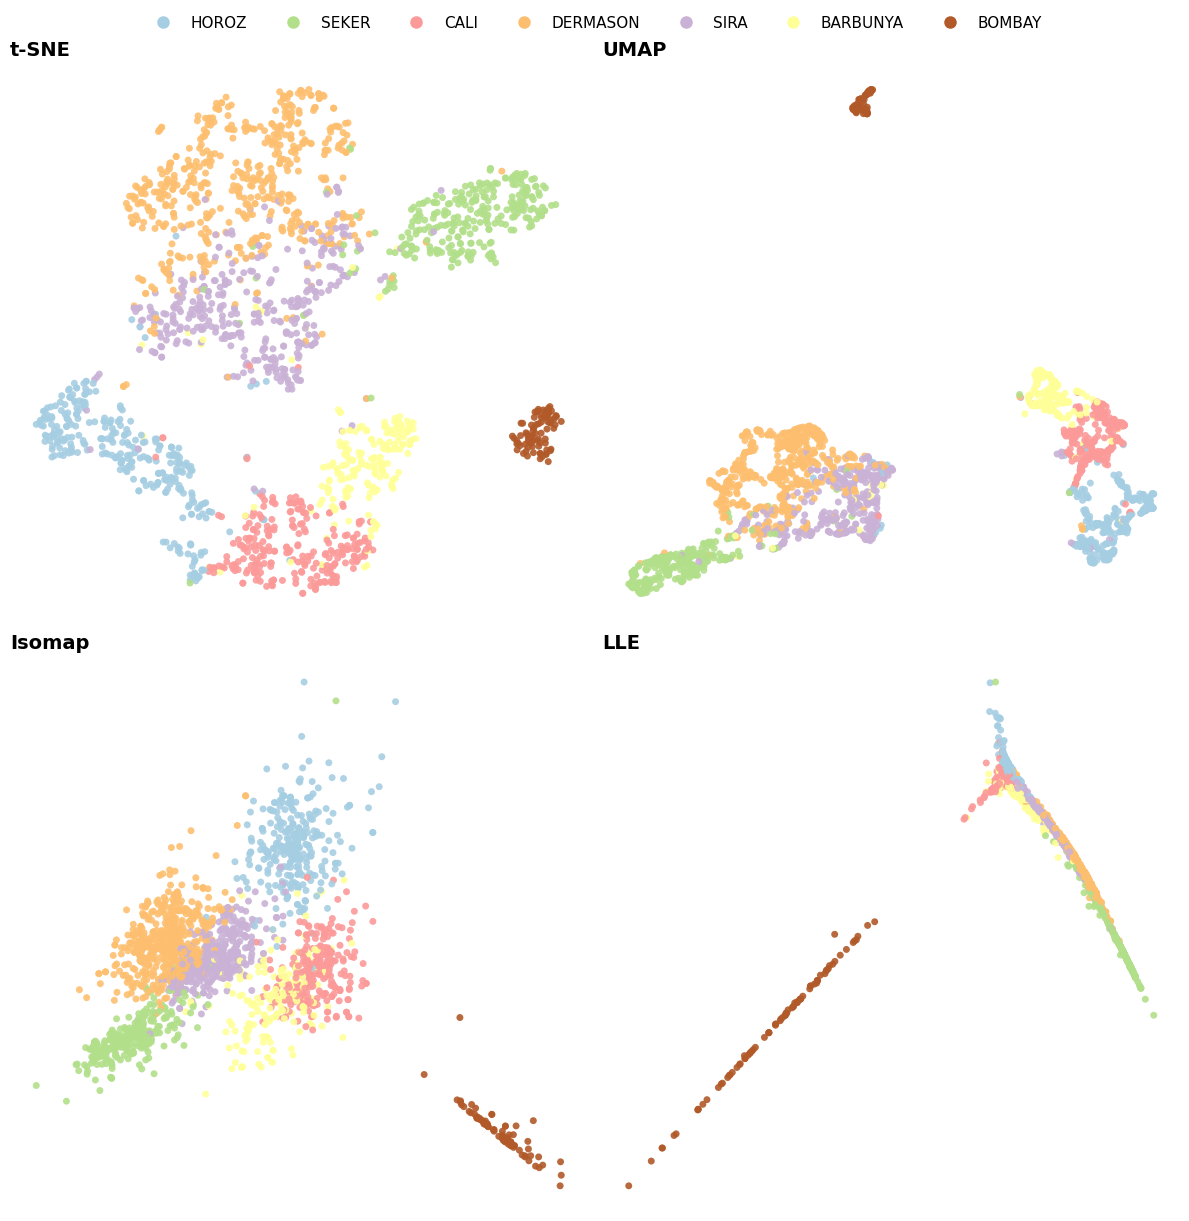

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, m in zip(axes.ravel(), METHODS):
    Z = embeddings[m]
    ax.scatter(Z[:, 0], Z[:, 1], c=y_codes, cmap=CLASS_CMAP, norm=CLASS_NORM,
               s=25, alpha=0.9, edgecolors="none", rasterized=True)
    ax.set_title(m, fontsize=14, fontweight="bold", loc="left")
    ax.axis("off")
fig.legend(handles=class_handles, loc="upper center", ncol=n_classes, frameon=False,
           fontsize=11, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
fig.savefig(OUT_DIR / "layouts.pdf", bbox_inches="tight")
plt.show()

## FADEx on every instance, for every method

In [8]:
explainers = {}
for m in METHODS:
    print(f"--- {m} ---")
    explainers[m] = FADEx(
        high_dim_data=X,
        low_dim_data=embeddings[m],
        n_neighbors=FADEX_NEIGHBORS,
        feature_names=feature_names,
        remove_const_feat=False,
        use_pca=False,            # 16 features <= 50 -> no local PCA
    )
    explainers[m]._fit_all()

phis = {m: np.abs(np.asarray(explainers[m].all_phis)) for m in METHODS}

--- t-SNE ---


[FADEx] Processing Instances:   0%|          | 0/2000 [00:00<?, ?instance/s]

--- UMAP ---


[FADEx] Processing Instances:   0%|          | 0/2000 [00:00<?, ?instance/s]

--- Isomap ---


[FADEx] Processing Instances:   0%|          | 0/2000 [00:00<?, ?instance/s]

--- LLE ---


[FADEx] Processing Instances:   0%|          | 0/2000 [00:00<?, ?instance/s]

## Explanation space

Each method's attributions are min–max normalised per feature, and the four sets of explanation vectors
(4 × 2,000) are clustered together.

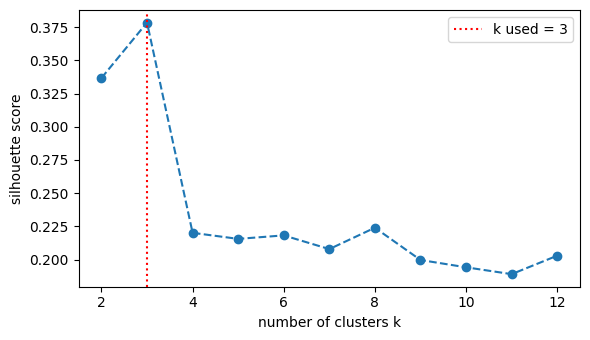

Silhouette optimum in this run: k = 3  |  k used (paper): 3


In [9]:
phis_norm = {m: MinMaxScaler().fit_transform(phis[m]) for m in METHODS}
E = np.vstack([phis_norm[m] for m in METHODS])               # (4 * N, n_features)
method_of_row = np.repeat(METHODS, N_SAMPLES)

# Silhouette search (diagnostic)
sil = [silhouette_score(E, KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(E))
       for k in K_RANGE]
best_k = list(K_RANGE)[int(np.argmax(sil))]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(list(K_RANGE), sil, "o--")
ax.axvline(N_CLUSTERS, color="red", linestyle=":", label=f"k used = {N_CLUSTERS}")
ax.set_xlabel("number of clusters k")
ax.set_ylabel("silhouette score")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Silhouette optimum in this run: k = {best_k}  |  k used (paper): {N_CLUSTERS}")

In [10]:
labels_raw = KMeans(n_clusters=N_CLUSTERS, random_state=SEED, n_init=10).fit_predict(E)

# Relabel clusters by size: 0 = largest, 1 = second largest, ...
order = np.argsort(-np.bincount(labels_raw))
remap = np.empty_like(order)
remap[order] = np.arange(N_CLUSTERS)
cluster_labels = remap[labels_raw]

clusters = {m: cluster_labels[i * N_SAMPLES:(i + 1) * N_SAMPLES] for i, m in enumerate(METHODS)}
counts = pd.crosstab(pd.Series(cluster_labels, name="cluster"), pd.Series(method_of_row, name="method"))[METHODS]
display(counts)

method,t-SNE,UMAP,Isomap,LLE
cluster,,,,
0,1488,1389,1330,1288
1,431,530,590,631
2,81,81,80,81


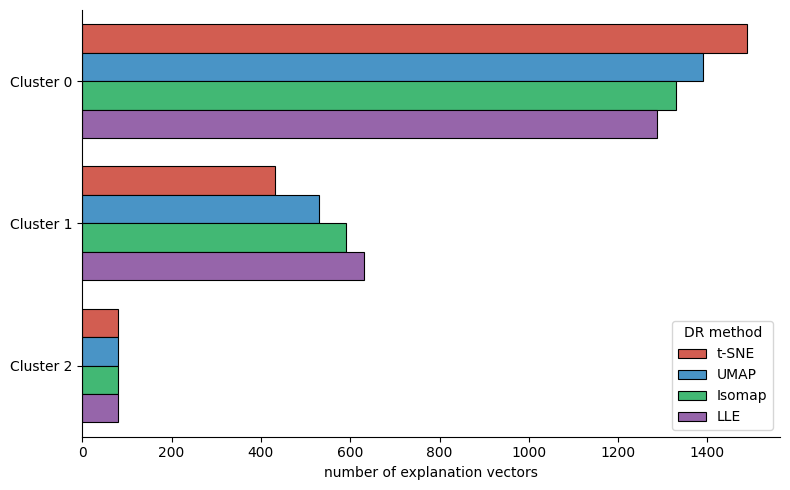

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(y=cluster_labels, hue=method_of_row, hue_order=METHODS, palette=METHOD_COLORS,
              edgecolor="black", linewidth=0.8, ax=ax)
ax.set_yticks(range(N_CLUSTERS), [f"Cluster {c}" for c in range(N_CLUSTERS)])
ax.set_xlabel("number of explanation vectors")
ax.set_ylabel("")
ax.legend(title="DR method", loc="lower right")
sns.despine()
plt.tight_layout()
fig.savefig(OUT_DIR / "cluster_counts.pdf", bbox_inches="tight")
plt.show()

## Agreement between methods

For every pair of methods, we compute the Spearman correlation between the attribution vectors of each instance and
average it over the 2,000 instances. Cosine similarity is shown for reference; the paper reports only Spearman.

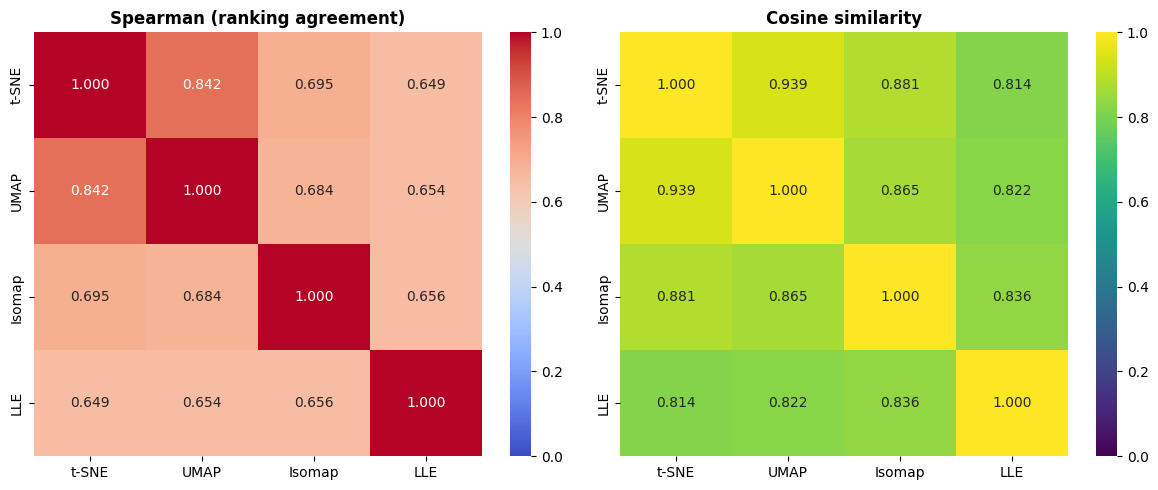

Spearman range: 0.649 (t-SNE–LLE)  to  0.842 (t-SNE–UMAP)
Paper:          0.649 (t-SNE–LLE)  to  0.842 (t-SNE–UMAP)


In [12]:
n_m = len(METHODS)
spearman_mat, cosine_mat = np.eye(n_m), np.eye(n_m)
for i in range(n_m):
    for j in range(i + 1, n_m):
        A, B = phis[METHODS[i]], phis[METHODS[j]]
        rho = [spearmanr(a, b)[0] for a, b in zip(A, B) if a.std() > 0 and b.std() > 0]
        spearman_mat[i, j] = spearman_mat[j, i] = np.nanmean(rho)
        cosine_mat[i, j] = cosine_mat[j, i] = np.mean(np.diag(cosine_similarity(A, B)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, mat, title, cmap in [(axes[0], spearman_mat, "Spearman (ranking agreement)", "coolwarm"),
                             (axes[1], cosine_mat, "Cosine similarity", "viridis")]:
    sns.heatmap(mat, annot=True, fmt=".3f", cmap=cmap, vmin=0, vmax=1,
                xticklabels=METHODS, yticklabels=METHODS, ax=ax)
    ax.set_title(title, fontweight="bold")
plt.tight_layout()
fig.savefig(OUT_DIR / "agreement.pdf", bbox_inches="tight")
plt.show()

pairs = [(spearman_mat[i, j], METHODS[i], METHODS[j]) for i in range(n_m) for j in range(i + 1, n_m)]
lo, hi = min(pairs), max(pairs)
print(f"Spearman range: {lo[0]:.3f} ({lo[1]}–{lo[2]})  to  {hi[0]:.3f} ({hi[1]}–{hi[2]})")
print("Paper:          0.649 (t-SNE–LLE)  to  0.842 (t-SNE–UMAP)")

## Per-cluster explanations

In [13]:
def top_features(method, cluster, n_top=N_TOP):
    # Mean attribution of a method's instances in a cluster, top-n features
    mask = clusters[method] == cluster
    mean_phi = phis[method][mask].mean(axis=0)
    idx = np.argsort(mean_phi)[::-1][:n_top]
    return [feature_names[i] for i in idx], mean_phi[idx]


def plot_top_features(cluster):
    fig, axes = plt.subplots(2, 2, figsize=(9, 7))
    for ax, m in zip(axes.ravel(), METHODS):
        names, vals = top_features(m, cluster)
        ax.barh(range(N_TOP), vals, color="green", edgecolor="black", alpha=0.8)
        ax.set_yticks(range(N_TOP), names, fontsize=11)
        ax.invert_yaxis()
        ax.set_xticks([])
        ax.set_title(f"{m}  (n = {(clusters[m] == cluster).sum()})", loc="left", fontweight="bold")
        sns.despine(ax=ax, bottom=True)
    fig.suptitle(f"Cluster {cluster} — top-{N_TOP} features", fontsize=14, fontweight="bold")
    plt.tight_layout()
    fig.savefig(OUT_DIR / f"cluster_{cluster}_top_features.pdf", bbox_inches="tight")
    plt.show()


def plot_cluster_members(cluster):
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))
    for ax, m in zip(axes.ravel(), METHODS):
        Z, mask = embeddings[m], clusters[m] == cluster
        ax.scatter(Z[~mask, 0], Z[~mask, 1], c="lightgray", s=10, alpha=0.3, edgecolors="none")
        ax.scatter(Z[mask, 0], Z[mask, 1], c=y_codes[mask], cmap=CLASS_CMAP, norm=CLASS_NORM,
                   s=25, alpha=0.9, edgecolors="none")
        ax.set_title(m, loc="left", fontweight="bold")
        ax.axis("equal")
        ax.axis("off")
    fig.legend(handles=class_handles, loc="upper center", ncol=n_classes, frameon=False,
               bbox_to_anchor=(0.5, 1.02))
    plt.tight_layout()
    fig.savefig(OUT_DIR / f"cluster_{cluster}_members.pdf", bbox_inches="tight")
    plt.show()

### Cluster 0

Paper finding: the methods agree. `ShapeFactor1` and `ShapeFactor2` rank first and second, and `MinorAxisLength`
and `AspectRatio` appear in the top-5 for t-SNE, UMAP and Isomap. The `ShapeFactor1` influence vectors (cluster 0
members coloured, other points in grey) show method-specific effects on the layout.

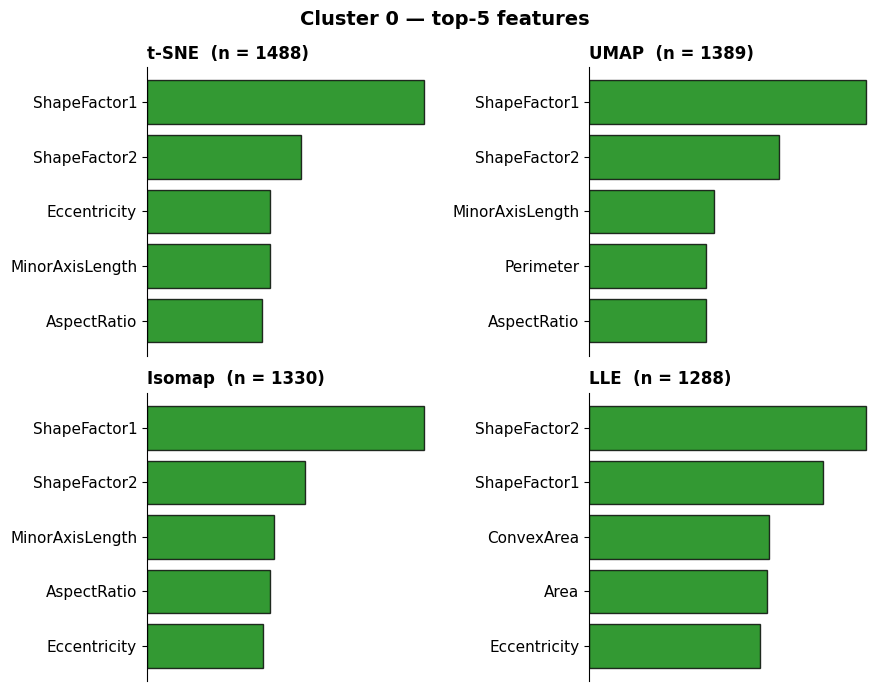

--- t-SNE: Feature Influence Vectors of ShapeFactor1 ---


[FADEx] Computing grid cells:   0%|          | 0/114 [00:00<?, ?it/s]

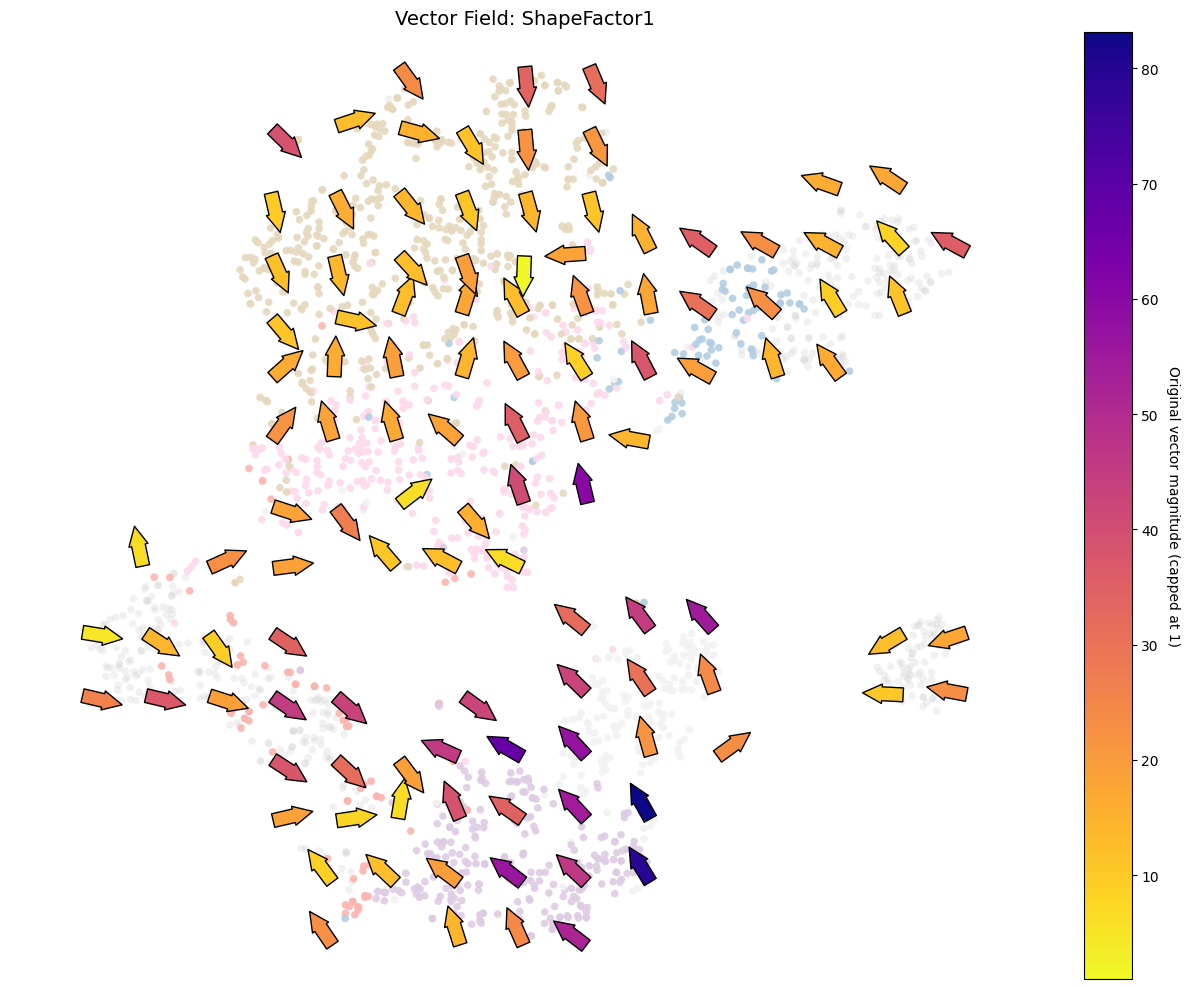

--- UMAP: Feature Influence Vectors of ShapeFactor1 ---


[FADEx] Computing grid cells:   0%|          | 0/49 [00:00<?, ?it/s]

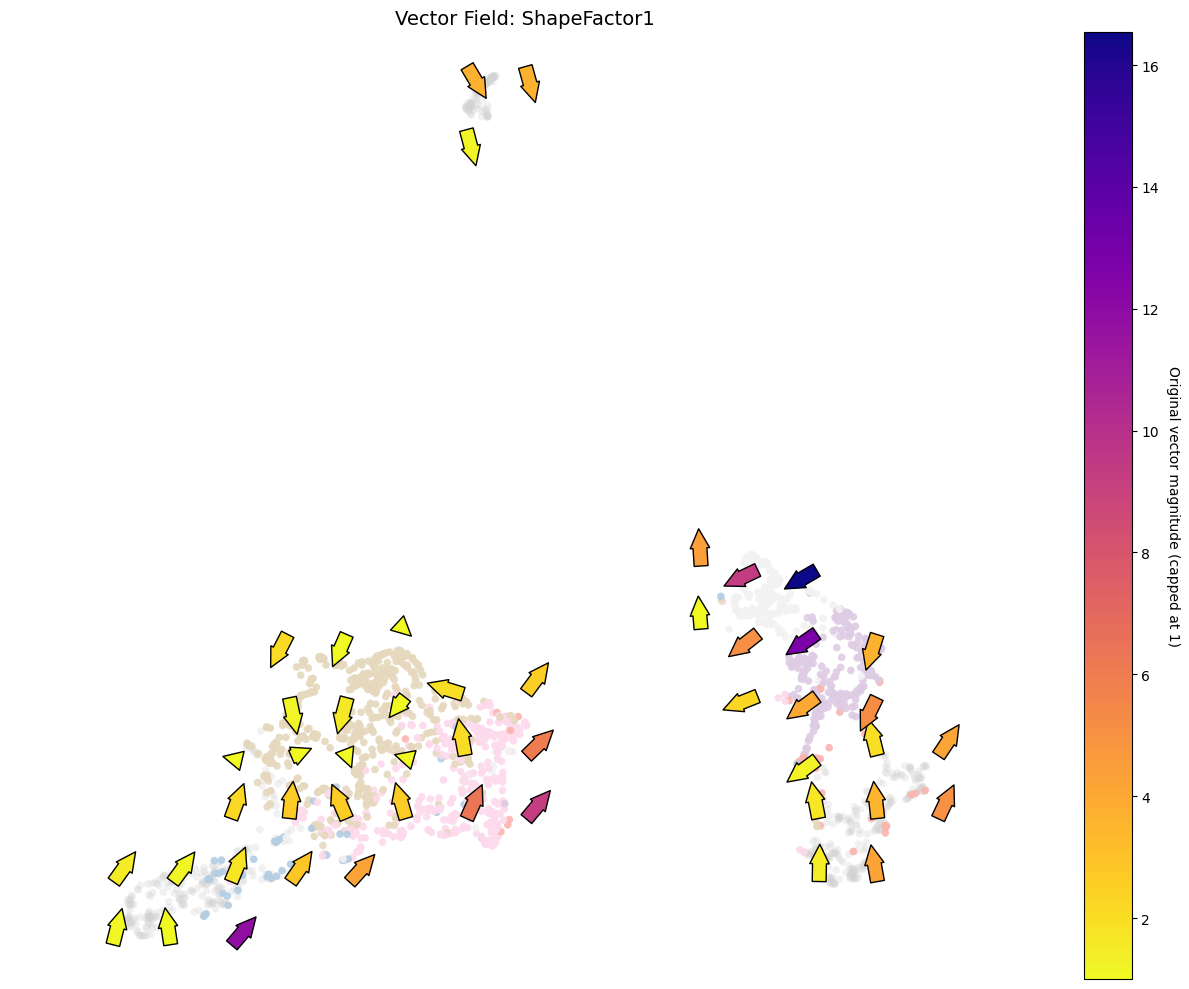

--- Isomap: Feature Influence Vectors of ShapeFactor1 ---


[FADEx] Computing grid cells:   0%|          | 0/79 [00:00<?, ?it/s]

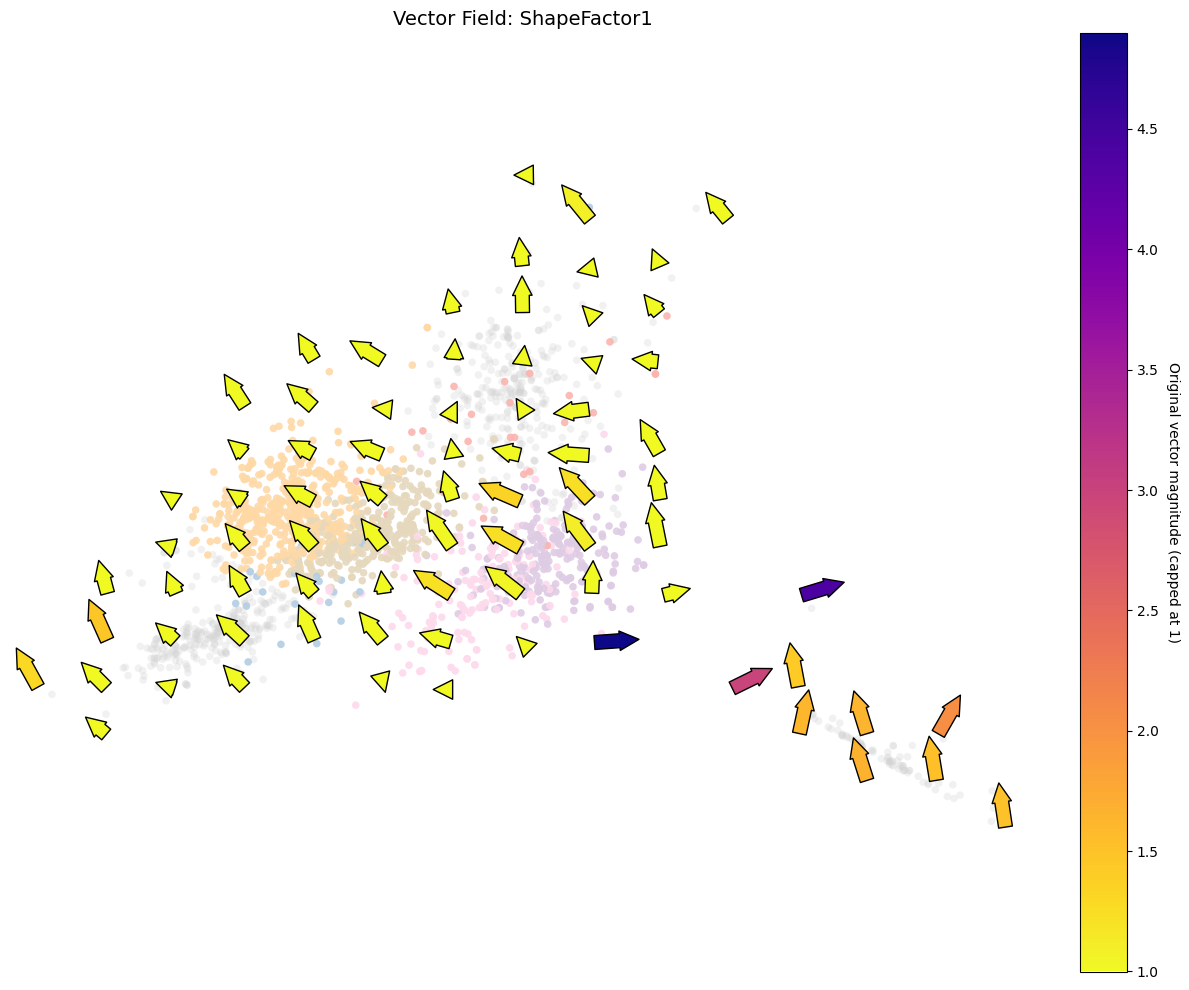

--- LLE: Feature Influence Vectors of ShapeFactor1 ---


[FADEx] Computing grid cells:   0%|          | 0/32 [00:00<?, ?it/s]

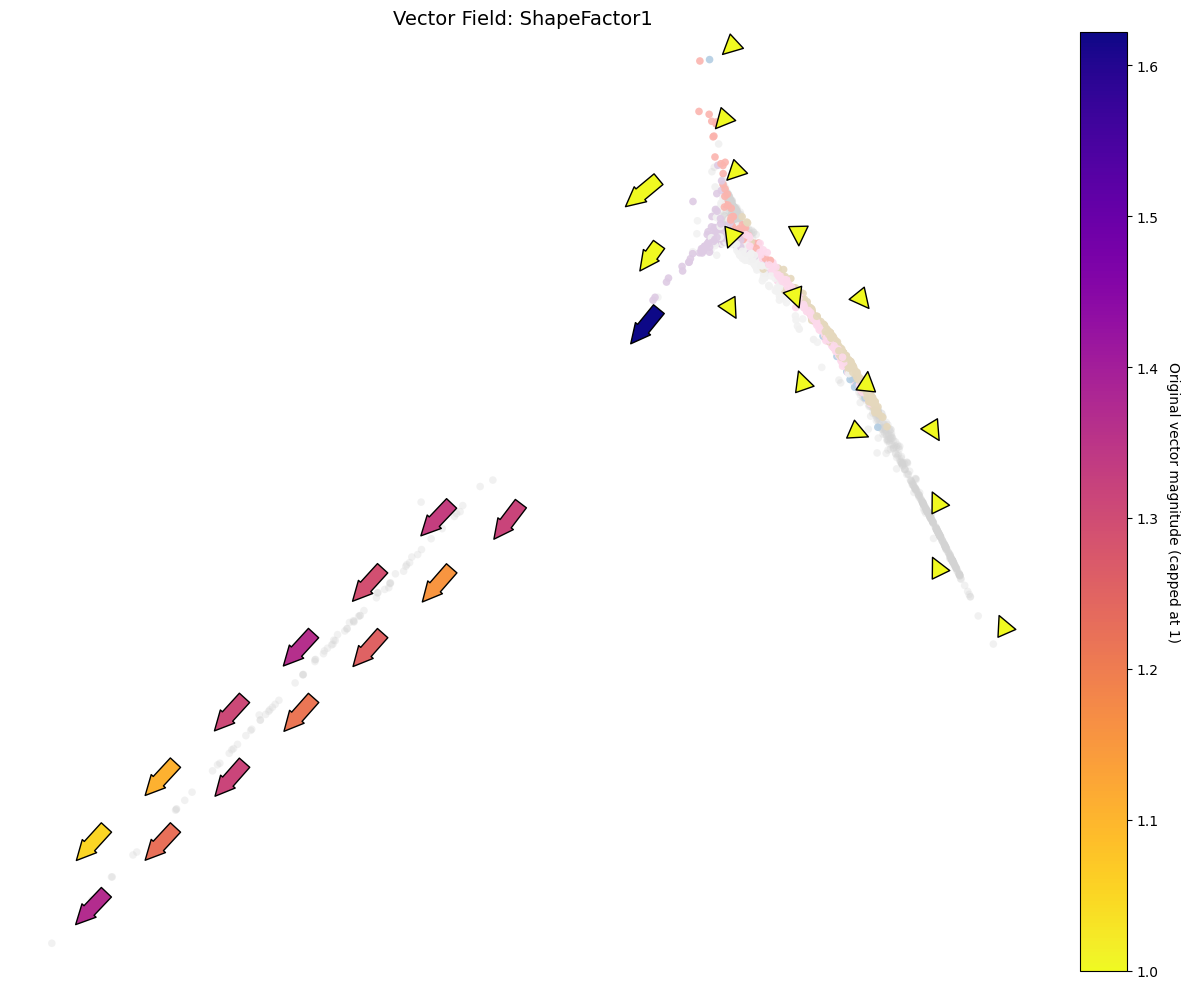

In [14]:
plot_top_features(0)

for m in METHODS:
    print(f"--- {m}: Feature Influence Vectors of {VECTOR_FEATURE} ---")
    explainers[m].plot_grid_feature_vectors(feature=VECTOR_FEATURE, labels=y_codes,
                                            mask=clusters[m] == 0, save_fig=True)

### Cluster 1

Paper finding: `AspectRatio`, `Eccentricity`, `ShapeFactor2` and `ShapeFactor3` are in the top-5 of every method.
Cluster 1 is made up mostly of *Seker* and *Horoz* beans, and those four features separate the two varieties.

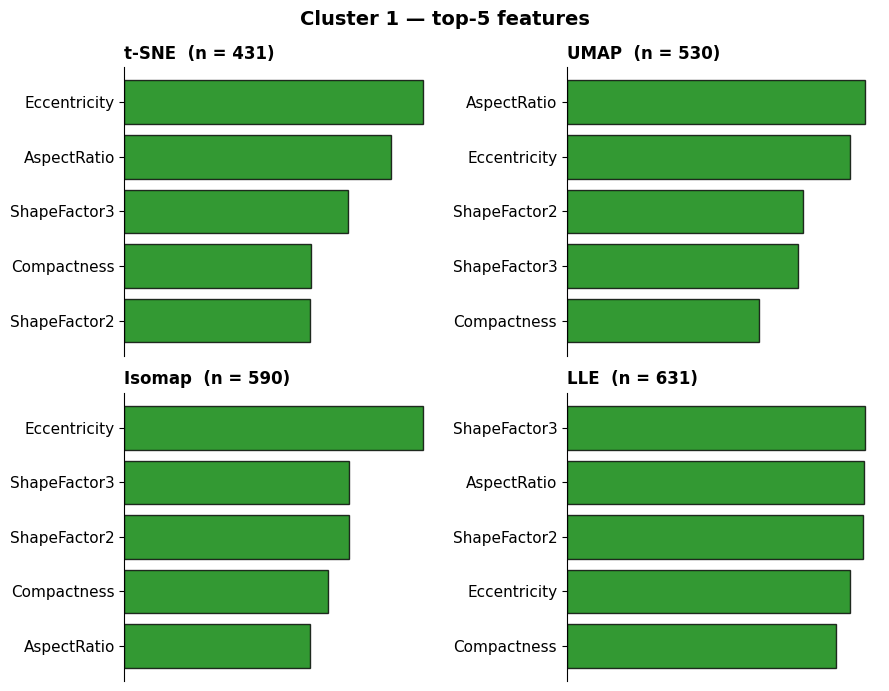

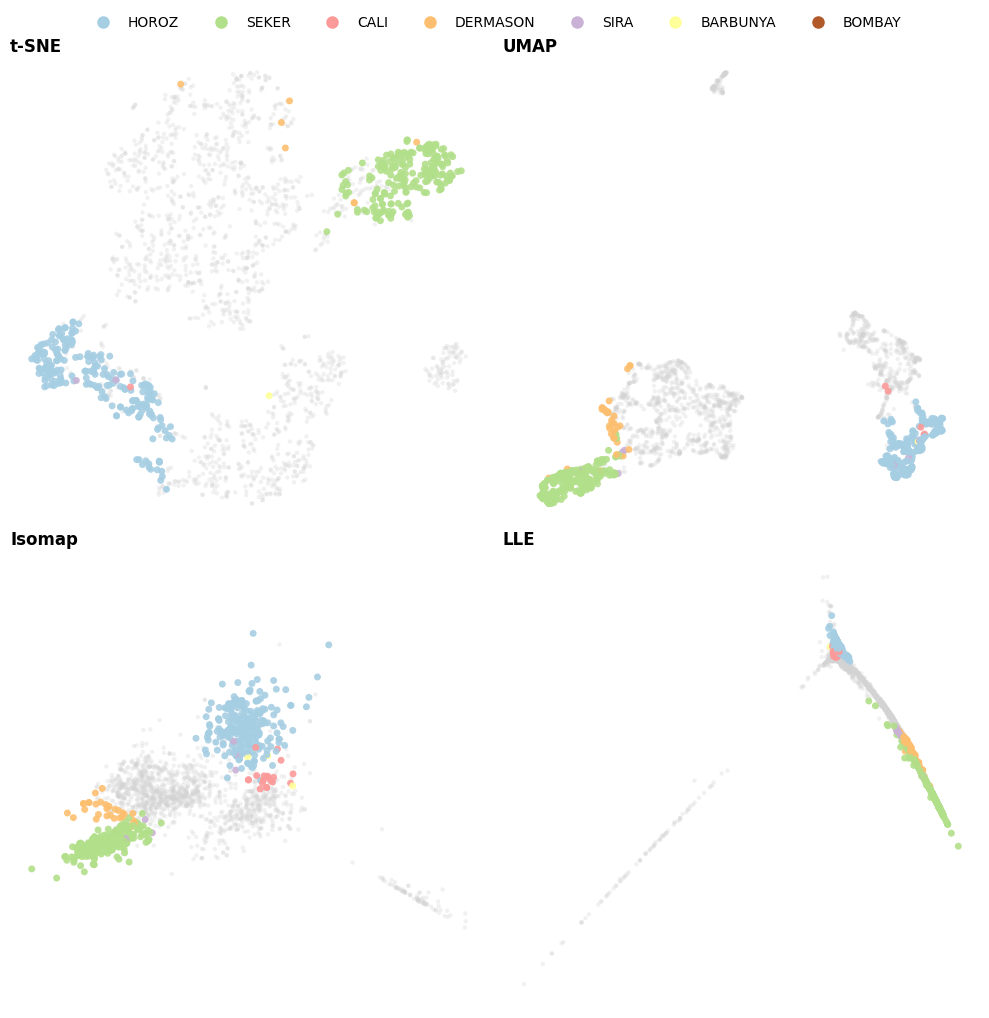

In [15]:
plot_top_features(1)
plot_cluster_members(1)

Features: ['Eccentricity', 'AspectRatio', 'ShapeFactor3', 'ShapeFactor2'] | Classes: ['HOROZ', 'SEKER']


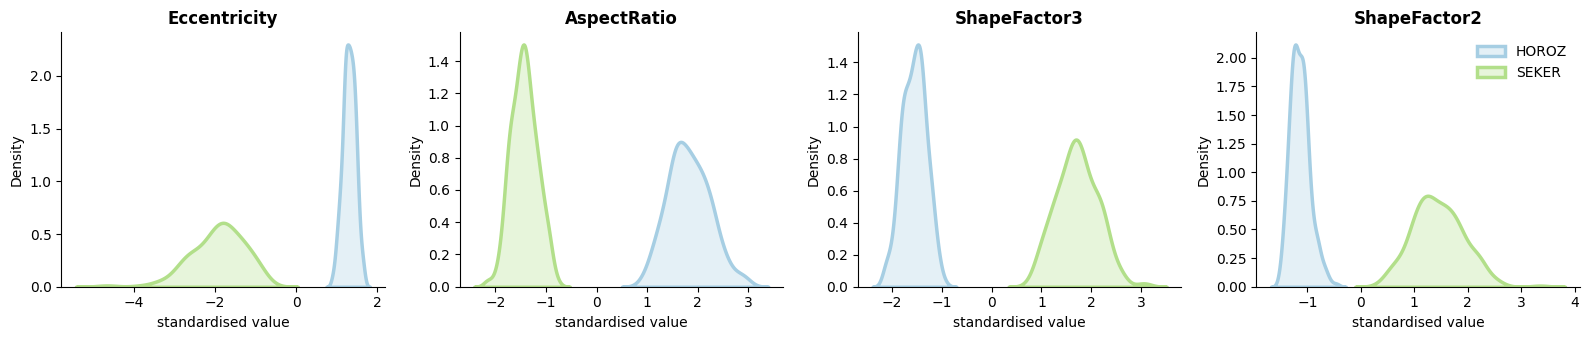

In [16]:
CLUSTER = 1

# Features: union of each method's top-3, in order of appearance (first four)
selected = []
for m in METHODS:
    for f in top_features(m, CLUSTER, n_top=3)[0]:
        if f not in selected:
            selected.append(f)
selected = selected[:4]

# Classes: the two most frequent varieties among the cluster members (any method)
member = np.zeros(N_SAMPLES, dtype=bool)
for m in METHODS:
    member |= clusters[m] == CLUSTER
top_classes = pd.Series(y_codes[member]).value_counts().index[:2].tolist()
print("Features:", selected, "| Classes:", [class_names[c] for c in top_classes])

fig, axes = plt.subplots(1, len(selected), figsize=(4 * len(selected), 3.5))
for ax, f in zip(np.atleast_1d(axes), selected):
    j = feature_names.index(f)
    for c in top_classes:
        sns.kdeplot(x=X[member & (y_codes == c), j], ax=ax, color=class_color(c), fill=True,
                    alpha=0.3, linewidth=2.5, label=str(class_names[c]))
    ax.set_title(f, fontweight="bold")
    ax.set_xlabel("standardised value")
    sns.despine(ax=ax)
np.atleast_1d(axes)[-1].legend(frameon=False)
plt.tight_layout()
fig.savefig(OUT_DIR / f"cluster_{CLUSTER}_distributions.pdf", bbox_inches="tight")
plt.show()